In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    r2_score,
    mean_squared_error
)

In [2]:
df = pd.read_csv("maintenance_servicehours.csv")


print(df)

       BoostPressure  EngineFuelRate  EngineLoad  EngineOilPressure  \
0               3.12           88.19       31.70             587.67   
1               8.23          109.86       34.60             692.82   
2               3.05           64.07       22.30             572.30   
3              12.03          104.47       33.50             685.22   
4              10.08           71.29       21.40             612.62   
...              ...             ...         ...                ...   
11495          55.45          229.27       72.27             473.37   
11496          51.15          157.42       45.83             527.75   
11497         117.30          326.18       98.63             489.15   
11498          51.38          186.85       50.67             497.75   
11499           6.65           21.80        9.50             397.45   

       EngineRpm  GroundSpeed  HaulDistance  Payload  TankFuelLevel  \
0        1360.65         0.00          0.00     0.00          33.24   
1    

<class 'pandas.DataFrame'>
RangeIndex: 11500 entries, 0 to 11499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BoostPressure      11500 non-null  float64
 1   EngineFuelRate     11500 non-null  float64
 2   EngineLoad         11500 non-null  float64
 3   EngineOilPressure  11500 non-null  float64
 4   EngineRpm          11500 non-null  float64
 5   GroundSpeed        11500 non-null  float64
 6   HaulDistance       11500 non-null  float64
 7   Payload            11500 non-null  float64
 8   TankFuelLevel      11500 non-null  float64
 9   GearSelect         11500 non-null  float64
 10  ServiceHours       11500 non-null  float64
dtypes: float64(11)
memory usage: 988.4 KB


Text(0.5, 0, 'Service Hours')

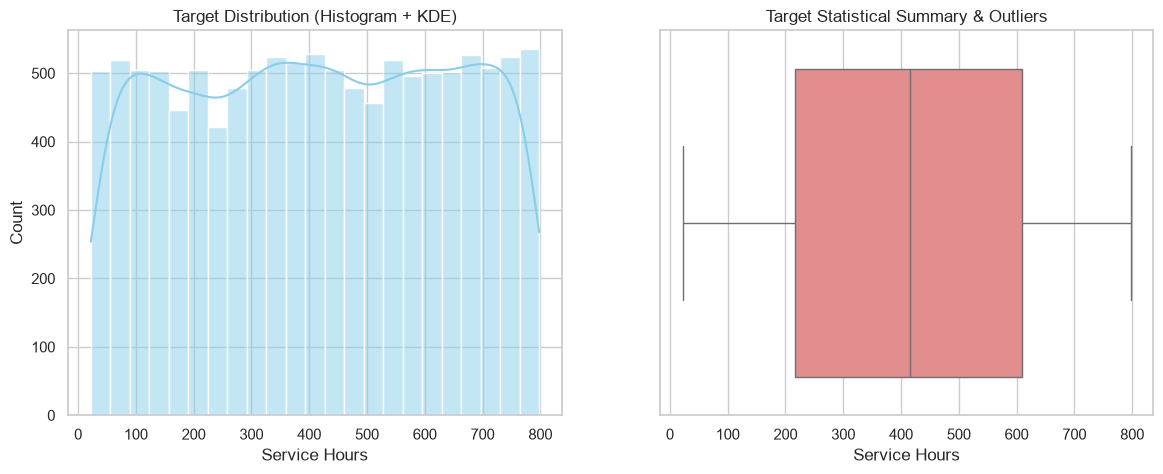

In [3]:
#EDA 

df.head()
df.info()
df.describe()
df.columns
df.shape
df.dtypes

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram + KDE
sns.histplot(df["ServiceHours"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Target Distribution (Histogram + KDE)")
axes[0].set_xlabel("Service Hours")

sns.boxplot(x=df["ServiceHours"], ax=axes[1], color="lightcoral")
axes[1].set_title("Target Statistical Summary & Outliers")
axes[1].set_xlabel("Service Hours")

count    11500.000000
mean       413.808729
std        225.510283
min         22.000000
25%        216.735945
50%        415.630830
75%        609.729707
max        797.913199
Name: ServiceHours, dtype: float64


Text(0.5, 1.0, 'Distribution (Skewness: -0.02)')

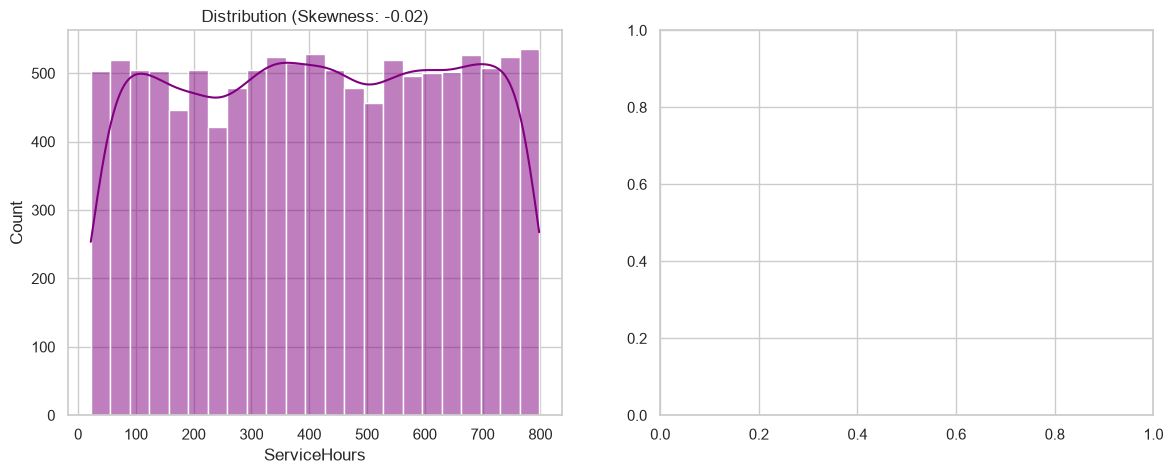

In [4]:
# X & Y defining

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

X = df.drop(columns=["ServiceHours"])
y = df["ServiceHours"]


num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print(y.describe())

sns.histplot(df["ServiceHours"], kde=True, ax=axes[0], color="purple")
skew_val = df["ServiceHours"].skew()
axes[0].set_title(f"Distribution (Skewness: {skew_val:.2f})")



In [5]:
# Preprocessing
print("Null values: ",df.isnull().sum())
print("Duplicated values: ",df.duplicated().sum())


Null values:  BoostPressure        0
EngineFuelRate       0
EngineLoad           0
EngineOilPressure    0
EngineRpm            0
GroundSpeed          0
HaulDistance         0
Payload              0
TankFuelLevel        0
GearSelect           0
ServiceHours         0
dtype: int64
Duplicated values:  0




#### Between -0.5 and 0.5	Symmetric (Normal / Uniform)	Mean	The data is balanced. The mean uses all data points and accurately finds the center.

#### > 0.5 or < -0.5	Highly Skewed (Right or Left)	Median	Skewed data has long tails or extreme outliers. The median is robust and won't get dragged away by outliers.


In [6]:
# Split the dataset into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    # StandardScaler()
)

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(sparse_output=False)
)

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])


print(X_train.columns.tolist())
print(preprocessor)


Training samples: 9200
Testing samples: 2300
['BoostPressure', 'EngineFuelRate', 'EngineLoad', 'EngineOilPressure', 'EngineRpm', 'GroundSpeed', 'HaulDistance', 'Payload', 'TankFuelLevel', 'GearSelect']
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['BoostPressure', 'EngineFuelRate',
                                  'EngineLoad', 'EngineOilPressure',
                                  'EngineRpm', 'GroundSpeed', 'HaulDistance',
                                  'Payload', 'TankFuelLevel', 'GearSelect']),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                           


MODEL: KNR_without_PCA
Best Hyper parameters: {'kneighborsregressor__algorithm': 'kd_tree', 'kneighborsregressor__n_neighbors': 3}

MODEL: KNR_PCA
Best Hyper parameters: {'kneighborsregressor__algorithm': 'kd_tree', 'kneighborsregressor__n_neighbors': 3}
PCA components retained: 2


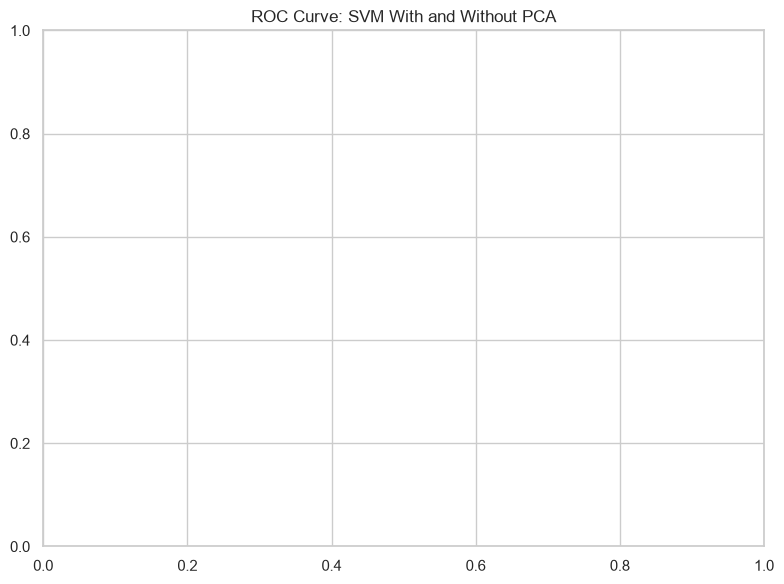

In [12]:
# Model Defining

model = {
    "KNR_without_PCA": make_pipeline(
        preprocessor,
        KNeighborsRegressor()
    ),
    "KNR_PCA": make_pipeline(
        preprocessor,
        PCA(n_components=0.95),
        KNeighborsRegressor()
    )
    
}

# Hyper Parameter Tuning

params = { "kneighborsregressor__n_neighbors": [1,2,3], "kneighborsregressor__algorithm":["kd_tree","ball_tree"]}

results = []
fig, ax = plt.subplots(figsize=(8, 6))

for name, pipeline in model.items():

    grid = GridSearchCV(pipeline, params, cv=5, scoring="r2", n_jobs=-1)

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    pred = grid.best_estimator_.predict(X_test)
    y_pred = grid.best_estimator_.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5

    residuals = y_test - y_pred

    #Classification metrics
    # accuracy_score(y_test, y_pred)
    # f1_score(y_test, y_pred)

    
    # confusion_matrix(y_test, y_pred)
    # classification_report(y_test, y_pred)

    results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "r2score": r2_score,
    
        # "ROC-AUC": auc
    })

    print("\n" + "=" * 50)
    print("MODEL:", name)
    print("=" * 50)

    print("Best Hyper parameters:", grid.best_params_)

    # print(f"F1-score : {f1:.4f}")
    # print(f"ROC-AUC  : {auc:.4f}")

    # print("\nConfusion Matrix:")
    # print(cm)


    # Display the number of PCA components retained.
    if "pca" in best_model.named_steps:
        print(
            "PCA components retained:",
            best_model.named_steps["pca"].n_components_
        )


plt.title("ROC Curve: SVM With and Without PCA")
plt.tight_layout()
plt.show()


10 -> 6


(np.int64(6), np.float64(0.9747867425097702))

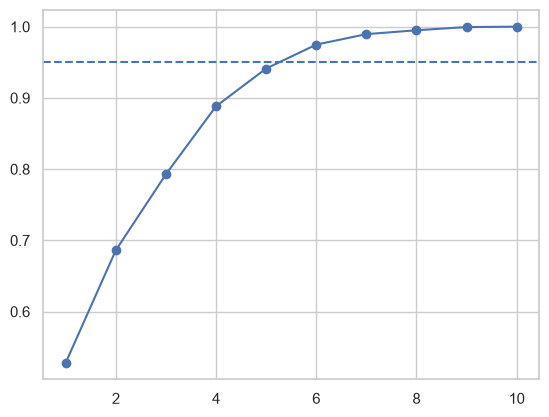

In [14]:
Xs = make_pipeline(SimpleImputer(strategy="median"),
StandardScaler()).fit_transform(X[num_cols])
pca = PCA().fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = np.argmax(cum >= 0.95) + 1 # min components for >= 95%variance
print(Xs.shape[1], "->", n95) # original vs reduced dimensions
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, linestyle="--")
# PCA with n_components=0.95 directly (picks n95 automatically)
pca95 = PCA(n_components=0.95).fit(Xs)
pca95.n_components_, pca95.explained_variance_ratio_.sum()
